# Классификация высокого макиавеллизма (MACH-IV)
- **Данные**: MACH-IV, Open Psychometrics, 2017–2019, добровольцы из интернета, 73 489 строк, рабочих 73 486 (3 неполные анкеты удалены).
- **Таргет предсказания**: "высокий макиавеллизм" - верхние 20% балла шкалы.
- **Классификация**: 2 класса (высокий/невысокий макиавеллизм), дисбаланс 20/80, нужны разные метрики (матрица ошибок, полнота и точность по классу 1, ROC-AUC), т.к. высокая accuracy не означает высокое качество модели: константная модель уже даёт 80%, а нужное может находить плохо.
- **Как строится целевая**: в данных готовой нет, строится из ответов Q1A–Q20A (шкала 1–5):
  1. **Разворот**: пункты 3, 4, 6, 7, 9, 10, 11, 14, 16, 17 сформулированы от обратного, поэтому их ответ заменяется на обратный (5 становится 1 и т.п.) — чтобы вывести корректную оценку (без разворота прямые и обратные пункты гасят друг друга).
  2. **Балл**: $S = \sum_{i \in \text{прямые}} Q_i + \sum_{i \in \text{обратные}} (6 - Q_i)$, диапазон от 20 до 100.
  3. **Класс**: y = 1, если S > 82 (доля класса 1 ≈ 19,9%), где порог — 80-й перцентиль балла, посчитанный только по обучающей выборке, чтобы правильно оценить качество работы на тестовой.
- **Зачем модель**: оценить склонность к макиавеллизму у человека, который не проходил тест, по другой информации о нём: личность (TIPI), демография, словарный чек-лист (VCL).
- **Исключаем из признаков** — всё, что существует только при прохождении теста; в сценарии применения этих данных нет (утечка данных), но причины разной силы:
  - Q*A — сам источник целевой: модель просто выучила бы формулу балла;
  - Q*E — время ответа на пункты несёт информацию о самих ответах;
  - Q*I — порядок вопросов случайный, т.е. ещё и шум;
  - introelapse — время на вводной странице теста;
  - testelapse — время на странице теста, по смыслу почти сумма Q*E, поэтому исключается по той же причине.



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

## 1. Чтение данных

In [2]:
df = pd.read_csv("data/data.csv", sep="\t")
df.shape

(73489, 105)

In [3]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 73489 entries, 0 to 73488
Columns: 105 entries, Q1A to major
dtypes: float64(64), int64(39), object(2)
memory usage: 58.9+ MB
None


In [4]:
rev = [f"Q{i}A" for i in (3, 4, 6, 7, 9, 10, 11, 14, 16, 17)]
items = df[[f"Q{i}A" for i in range(1,21)]].copy()
items[rev] = 6 - items[rev]

S = items.sum(axis=1, min_count=20)
print(S)

0        75.0
1        91.0
2        98.0
3        78.0
4        85.0
         ... 
73484    59.0
73485    90.0
73486    69.0
73487    53.0
73488    64.0
Length: 73489, dtype: float64


In [5]:
print(S.describe())

count    73486.000000
mean        67.684294
std         15.777876
min         20.000000
25%         56.000000
50%         68.000000
75%         80.000000
max        100.000000
dtype: float64


In [6]:
print(S.isna().sum())

3


In [7]:
S = S.dropna()
print(S.describe())
df = df.loc[S.index]
df.shape

count    73486.000000
mean        67.684294
std         15.777876
min         20.000000
25%         56.000000
50%         68.000000
75%         80.000000
max        100.000000
dtype: float64


(73486, 105)

In [8]:
print(S.value_counts().min())

3


## 2. Разбиение
Возьмём test_size = 0.2: в тесте ≈ 14 700 объектов, из них ≈ 2 940 класса 1 (20% теста). Этого хватает: случайный разброс метрик по классу 1 — около ±1–2 п.п., меньше ожидаемых различий между моделями.

In [9]:
from sklearn.model_selection import train_test_split
df_train, df_test, S_train, S_test = train_test_split(df, S, test_size=0.2, stratify=S, random_state=42)
print(df_train.shape, df_test.shape, S_train.shape, S_test.shape)

(58788, 105) (14698, 105) (58788,) (14698,)


In [10]:
t = S_train.quantile(0.8)

y_train = (S_train > t)
y_test = (S_test > t)
print(f"{t}, {y_train.mean():.3f}, {y_test.mean():.3f}")

82.0, 0.199, 0.199


Микроэксперимент

In [11]:
t_train = S_train.quantile(0.8)   
t_test  = S_test.quantile(0.8)   
t_all   = S.quantile(0.8)       
print(f"train: {t_train}, test: {t_test}, все: {t_all}")

train: 82.0, test: 82.0, все: 82.0


Пороги не различаются, так как выборка достаточно большая и перцентиль не сильно "гуляет"

## 3. EDA

### 3а. Первичный осмотр (сырые данные)

In [12]:
eda = df_train.assign(S=S_train, y=y_train.astype(int))
num = ["age", "familysize", "surveyelapse", "screenw", "screenh"]
eda[num].describe()

,age,familysize,surveyelapse,screenw,screenh
count,5.878800e+04,5.878800e+04,5.878800e+04,58785.000000,58785.000000
mean,1.997189e+02,3.654721e+04,2.744781e+03,968.670698,802.037561
std,3.734745e+04,8.856978e+06,1.521006e+05,609.139712,182.224224
min,1.300000e+01,0.000000e+00,2.000000e+00,0.000000,0.000000
25%,1.900000e+01,2.000000e+00,1.460000e+02,375.000000,667.000000
50%,2.500000e+01,2.000000e+00,1.860000e+02,834.000000,768.000000
75%,3.600000e+01,3.000000e+00,2.510000e+02,1440.000000,900.000000
max,9.000009e+06,2.147484e+09,2.812267e+07,7680.000000,2960.000000


In [13]:
tipi = [f"TIPI{i}" for i in range(1, 11)]
eda[tipi].describe()

,TIPI1,TIPI2,TIPI3,TIPI4,TIPI5,TIPI6,TIPI7,TIPI8,TIPI9,TIPI10
count,58788.000000,58788.000000,58788.000000,58788.000000,58788.000000,58788.000000,58788.000000,58788.000000,58788.000000,58788.000000
mean,3.985796,4.432826,5.175172,3.971848,5.650252,4.555045,4.941298,3.511924,4.698391,2.653161
std,2.006738,1.900925,1.712669,2.044283,1.473485,2.005491,1.799889,1.981332,1.861653,1.714177
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,3.000000,4.000000,2.000000,5.000000,3.000000,4.000000,2.000000,3.000000,1.000000
50%,4.000000,5.000000,6.000000,4.000000,6.000000,5.000000,5.000000,3.000000,5.000000,2.000000
75%,6.000000,6.000000,6.000000,6.000000,7.000000,6.000000,6.000000,5.000000,6.000000,4.000000
max,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000


In [14]:
for c in ["education", "married", "urban", "religion"]:
    print(eda[c].value_counts(dropna=False).sort_index(), "\n")

education
0      710
1     6379
2    21560
3    19903
4    10236
Name: count, dtype: int64 

married
0      235
1    41952
2    12069
3     4532
Name: count, dtype: int64 

urban
0      505
1    11353
2    22357
3    24573
Name: count, dtype: int64 

religion
0       894
1     12106
2     13871
3      1221
4      7920
5       472
6      5698
7      6261
8      1614
9       592
10     2027
11      129
12     5983
Name: count, dtype: int64 



In [15]:
eda["country"].value_counts(dropna=False).head(10)

country
US      27285
GB       4396
CA       3787
AU       2193
IN       1282
HU       1175
NONE     1111
DE       1028
PH        864
NL        836
Name: count, dtype: int64

In [16]:
eda["gender"].value_counts(dropna=False) 

gender
1    31691
2    26321
3      669
0      107
Name: count, dtype: int64

In [17]:
(eda[tipi] == 0).sum() 

TIPI1     421
TIPI2     474
TIPI3     542
TIPI4     501
TIPI5     440
TIPI6     464
TIPI7     516
TIPI8     593
TIPI9     448
TIPI10    536
dtype: int64

**Выбросы (явно невозможные значения):** age — max 9000009.0; familysize — max 2147483647.0; surveyelapse — max 28122672.0 с (≈ 325 дней, долго думал над ответами, наверное).
**Скрытые пропуски (коды, которых нет в кодбуке):** screenw/screenh — 0.0/0.0; gender = 0 — 107 чел.; education = 0 — 710; ещё: нули в married, urban и religion; TIPI = 0: 420–590 человек в каждом из 10 пунктов (шкала 1–7); country = NONE: 1 111 человек, 7-е место в топе; familysize = 0: «сколько детей у матери, включая тебя» не может быть 0.
**Порядок дальше:** сначала чистка (пп. 4–5), потом графики и корреляции (3б), потому, что некоторые оценки очень чувствительны к экстремальным значениям.

## 4. Чистка выбросов

In [18]:
print(df_train["surveyelapse"].quantile([0.5, 0.9, 0.99, 0.999])) 
print((df_train["familysize"] > 15).sum())
lim = df_train["surveyelapse"].quantile(0.99)
cat_cols = ["education", "urban", "gender", "engnat", "hand", "religion", "orientation", "race", "voted", "married"]

0.500       186.000
0.900       367.000
0.990      2581.040
0.999    283576.944
Name: surveyelapse, dtype: float64
28


Обрезаем по 99-му квантилю train (~43 мин): выше — уже не поведение, а брошенная вкладка; 90-й обрезал бы 10% реальных ответов.
Строк с размером семьи больше 15 всего 28, из них есть как минимум одно 2147483647.0, так что отсекаем.
age → NaN, surveyelapse → clip: возраст 9 000 009 — ошибка ввода, настоящий возраст неизвестен, любая замена была бы выдумкой. А про 325 дней на анкете придется тоже обрезать; обрезка до 43 мин сохраняет факт долгого прохождения и убирает только невозможную величину.

In [19]:
def clean(d):
    d = d.copy()
    d.loc[(d["age"] < 13) | (d["age"] > 90), "age"] = np.nan    
    d[cat_cols] = d[cat_cols].replace(0, np.nan)               
    d["country"] = d["country"].replace("NONE", np.nan)
    d["surveyelapse"] = d["surveyelapse"].clip(upper=lim)  
    d[tipi] = d[tipi].replace(0, np.nan) 
    d[["screenw", "screenh"]] = d[["screenw", "screenh"]].replace(0, np.nan)  
    d.loc[(d["familysize"] < 1) | (d["familysize"] > 15), "familysize"] = np.nan 
    d["fake"] = d[["VCL6", "VCL9", "VCL12"]].sum(axis=1)               
    d["major"] = d["major"].str.strip().str.lower().fillna("нет высшего")       
    return d

In [20]:
df_train = clean(df_train)
df_test  = clean(df_test)

In [21]:
print(df_train[num].describe(), df_test[num].describe())

                age    familysize  surveyelapse       screenw       screenh
count  58762.000000  56944.000000  58788.000000  58694.000000  58694.000000
mean      29.259896      2.629636    250.752339    970.172539    803.281051
std       12.926568      1.385745    291.691407    608.415493    179.605852
min       13.000000      1.000000      2.000000    176.000000    125.000000
25%       19.000000      2.000000    146.000000    375.000000    667.000000
50%       25.000000      2.000000    186.000000    854.000000    768.000000
75%       36.000000      3.000000    251.000000   1440.000000    900.000000
max       90.000000     15.000000   2581.040000   7680.000000   2960.000000                 age    familysize  surveyelapse       screenw       screenh
count  14694.000000  14248.000000  14698.000000  14674.000000  14674.000000
mean      29.110725      2.627737    247.428238    967.181273    802.053292
std       12.905271      1.390628    282.477413    610.498850    180.270668
min       13

## 5. Пропуски

In [22]:
eda = df_train.assign(S=S_train, y=y_train.astype(int))

In [23]:
excl = [c for c in df_train.columns if c[0] == "Q" and c[-1] in "AEI"] + ["introelapse", "testelapse"]
na = df_train.drop(columns=excl).isna().sum()
print(na[na > 0].sort_values(ascending=False))
print(df_train.drop(columns=excl).isna().any(axis=1).mean())

familysize     1844
orientation    1122
country        1118
religion        894
race            878
education       710
TIPI8           593
TIPI3           542
TIPI10          536
TIPI7           516
urban           505
TIPI4           501
TIPI2           474
TIPI6           464
voted           461
TIPI9           448
TIPI5           440
TIPI1           421
married         235
hand            233
gender          107
screenw          94
screenh          94
engnat           94
age              26
dtype: int64
0.1315574607062666


In [24]:
for c in ["religion", "gender", "orientation", "country"]:
    print(eda.groupby(eda[c].isna())["y"].agg(["mean", "size"]), "\n")
print("major пуст до заполнения:", round(df.loc[df_train.index, "major"].isna().mean(), 4))

              mean   size
religion                 
False     0.199451  57894
True      0.145414    894 

            mean   size
gender                 
False   0.198684  58681
True    0.168224    107 

                 mean   size
orientation                 
False        0.199892  57666
True         0.133690   1122 

             mean   size
country                 
False    0.197902  57670
True     0.236136   1118 

major пуст до заполнения: 0.3567


In [25]:
ordc = tipi + ["education"]
pd.DataFrame({"median": eda[ordc].median(), "mode": eda[ordc].mode().iloc[0]})

,median,mode
TIPI1,4.0,6.0
TIPI2,5.0,5.0
TIPI3,6.0,6.0
TIPI4,4.0,5.0
TIPI5,6.0,7.0
TIPI6,5.0,5.0
TIPI7,5.0,6.0
TIPI8,3.0,5.0
TIPI9,5.0,6.0
TIPI10,2.0,1.0


**Что видим:**
- `major` пуст у 35.7% строк train — по решению «пусто → нет высшего» это не пропуск, а категория (заполняется в `clean`). Остальные пропуски — у 13.2% строк; удалять их нельзя: потеряли бы каждую восьмую анкету, а сам пропуск несёт информацию (см. ниже).
- Пропуск несёт информацию: среди не указавших религию доля высокого макиавеллизма 14.54% против 20% у ответивших; ориентация — 13.36% против 20%; страна — 23.61% против 19.79%. У `gender` всего 107 пропусков — разница может быть шумом.
- Мода и медиана у TIPI расходятся (например, TIPI1: 6.0 против 4.0, TIPI8: 5.0 против 3.0).

**Решения:**
- числовые → медиана (так как у нас довольно увесистый правый хвост);
- порядковые → медиана (так как мы ничего не знаем о человеке);
- категориальные → отдельная категория «не указано» (она сама по себе тоже несет информацию);
- `major`: пусто → «нет высшего».

Заполнение — в пайплайне (`SimpleImputer`), параметры только по train.
        

## 3б. Визуализация (после чистки)

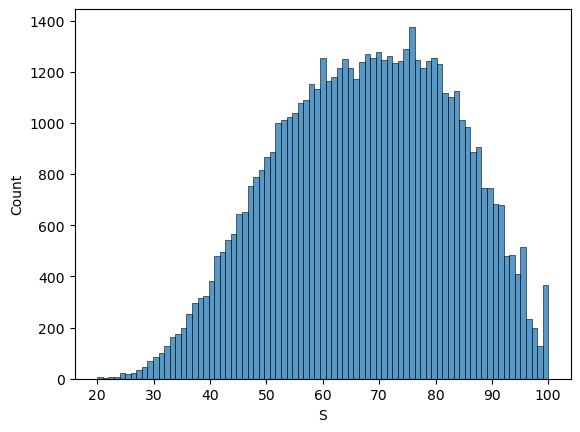

In [26]:
sns.histplot(data=eda, x="S", bins=81)
plt.show()

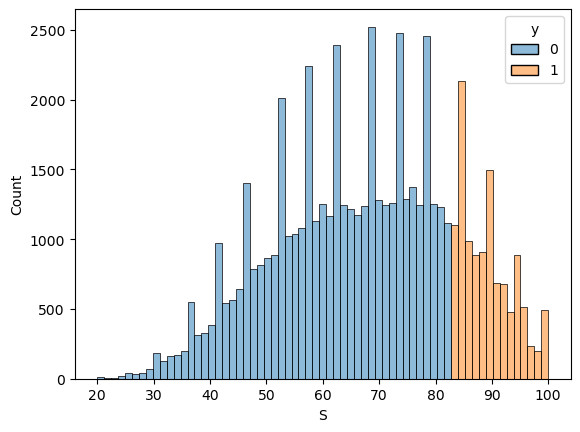

In [27]:
sns.histplot(data=eda, x="S", hue="y")
plt.show()

Распределение близко к симметричному, колоколообразное (среднее 67.7 ≈ медиане 68, σ = 15.8). Порог 82 отсекает правый хвост — это примерно 20% людей. Класс 1 на второй гистограмме — оранжевый.

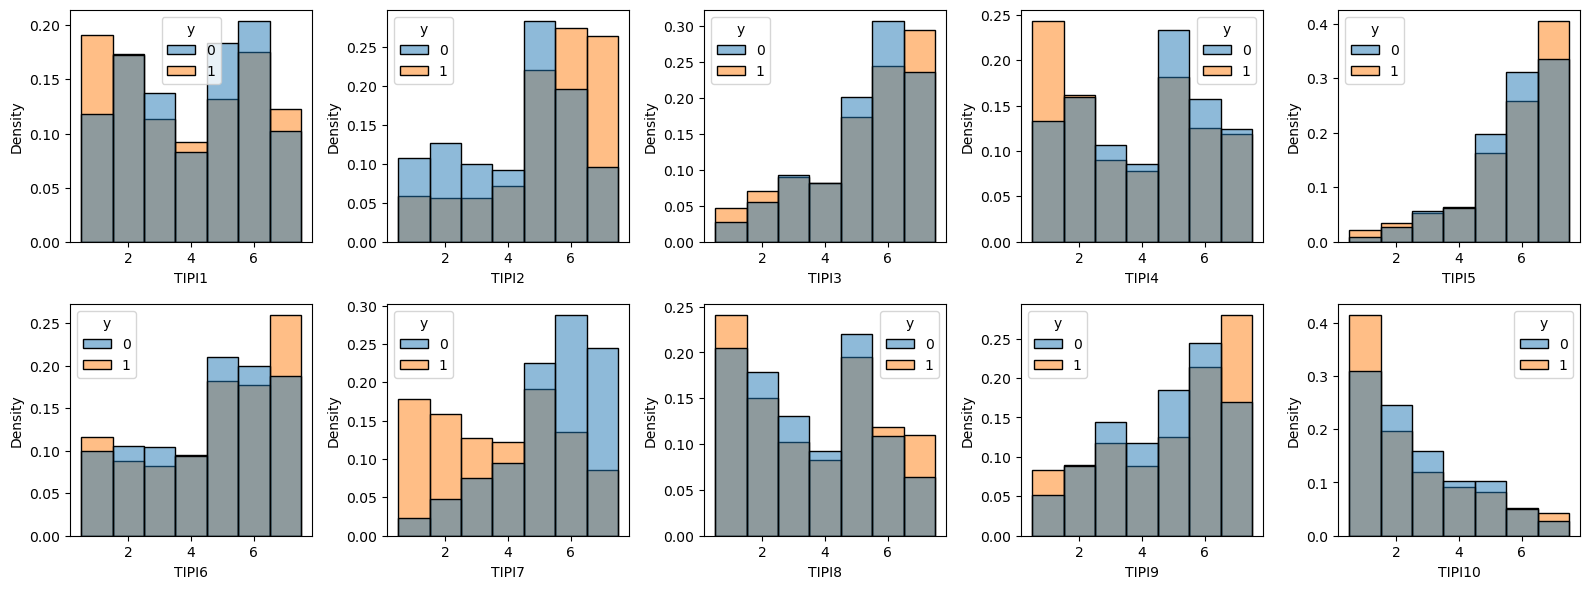

In [28]:
fig, axes = plt.subplots(2, 5, figsize=(16, 6))
for ax, c in zip(axes.flat, tipi):
    sns.histplot(data=eda, x=c, hue="y", stat="density", common_norm=False, ax=ax, discrete=True)
plt.tight_layout(); plt.show()

Сильнее всего распределения классов расходятся у TIPI2 и TIPI7: у класса 1 TIPI2 сдвинут вверх, TIPI7 вниз. У остальных пунктов классы почти совпадают.

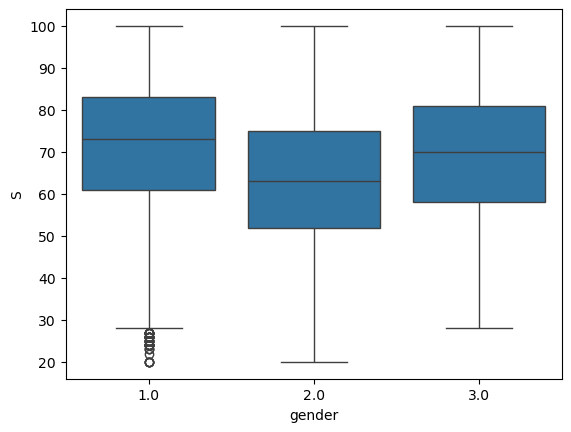

In [29]:
sns.boxplot(data=eda, x="gender", y="S")
plt.show()

У мужчин (gender = 1) медианный балл ≈ 73, у женщин (2) ≈ 63, у «другое» (3) ≈ 70: разница медиан около 10 баллов — заметнее, чем у большинства пунктов TIPI. Пол — категориальный признак, поэтому в корреляциях Спирмена его нет, но в модель он входит через one-hot. Группа «другое» маленькая (669 чел.), её медиану стоит читать осторожно.

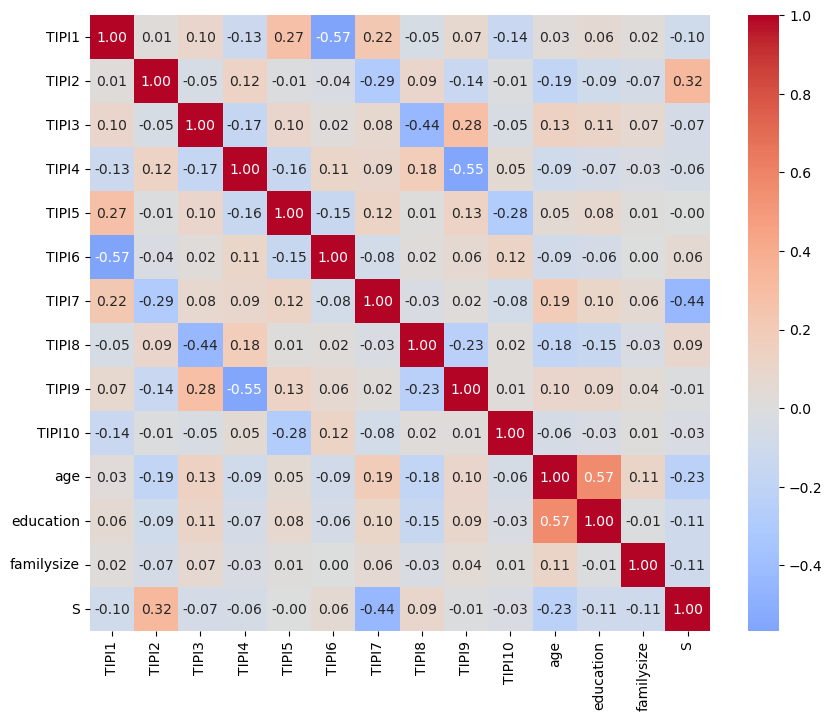

TIPI7        -0.442860
age          -0.229504
familysize   -0.106251
education    -0.106155
TIPI1        -0.099420
TIPI3        -0.071274
TIPI4        -0.055722
TIPI10       -0.033535
TIPI9        -0.005745
TIPI5        -0.000775
TIPI6         0.059428
TIPI8         0.091958
TIPI2         0.322829
Name: S, dtype: float64

In [30]:
cc = tipi + ["age", "education", "familysize", "S"]
corr = eda[cc].corr(method="spearman")
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0); plt.show()
corr["S"].drop("S").sort_values()
        

Сильнее всего с баллом связаны TIPI7 «сочувствующий, тёплый» (ρ = −0.44) и TIPI2 «критичный, склонный спорить» (ρ = +0.32): вполне логично, тк искренне «сочувствующий, тёплый» вряд ли будет использовать других людей, а вот «критичный, склонный спорить» зачастую может преследовать цель навязывания своей воли через спор и критику. Из демографии — возраст (ρ = −0.23): у старших в среднем ниже склонность к манипулятивности. Остальные |ρ| ≤ 0.11.

<Axes: xlabel='age', ylabel='S'>

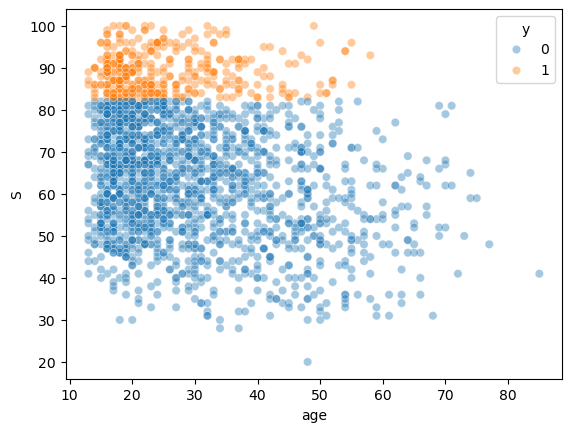

In [31]:
smp = eda.sample(2000, random_state=42)
sns.scatterplot(data=smp, x="age", y="S", hue="y", alpha=0.4)

Большинство респондентов — 15–35 лет. Класс 1 (оранжевый, S > 82) встречается в основном у молодых; среди старших 40–50 лет его доля заметно меньше, после 55 он почти не встречается. Облако в целом слабо наклонено вниз (ρ = −0.23): возраст сдвигает распределение балла, но сам по себе классы не разделяет.

In [32]:
eda.groupby("education").agg(share_y=("y", "mean"), age_med=("age", "median"), n=("y", "size")) 

,share_y,age_med,n
education,,,
1.0,0.252077,16.0,6379
2.0,0.220362,21.0,21560
3.0,0.177863,29.0,19903
4.0,0.159144,34.0,10236


In [33]:
eda[eda["age"] >= 25].groupby("education")["y"].agg(["mean", "size"])

,mean,size
education,,
1.0,0.247740,553
2.0,0.162954,7407
3.0,0.152282,13626
4.0,0.148315,8873


Доля высокого макиавеллизма падает с образованием (25.2% → 22.0% → 17.8% → 15.9%), но медианный возраст растёт с 16 до 34 лет, а возраст сам связан с баллом (ρ = −0.23). Среди людей 25+: доли у уровней 2–4 почти равны (16,3% → 15,2% → 14,8%). Вывод: падение доли с образованием в основном объясняется возрастом.

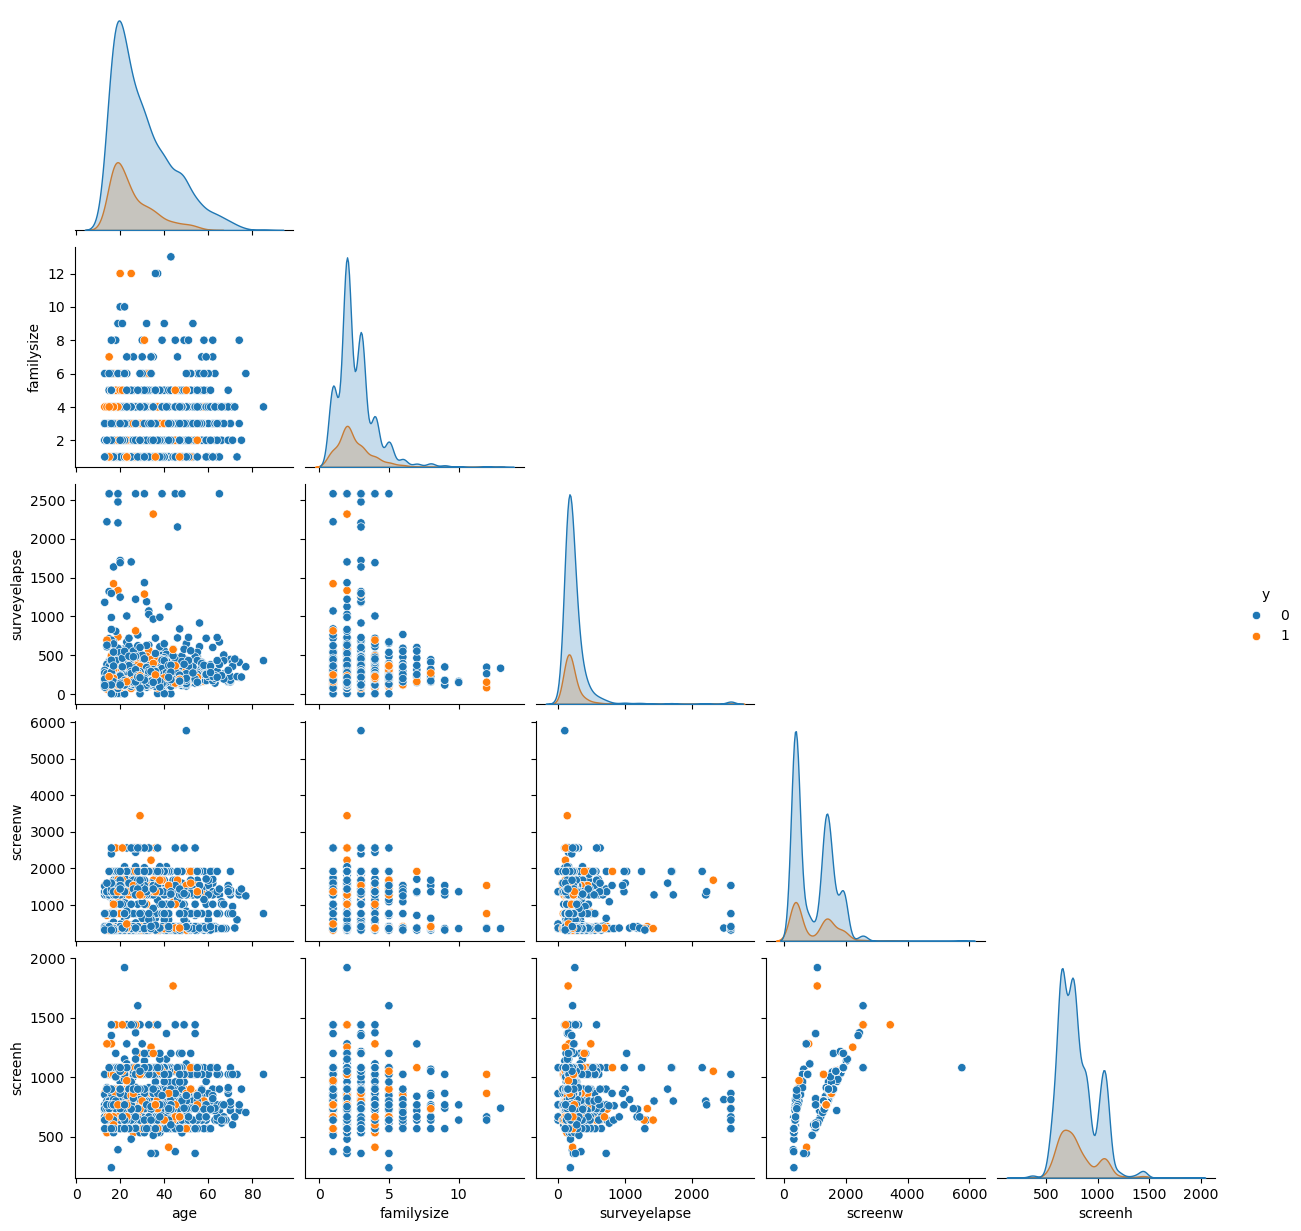

In [34]:
sns.pairplot(smp[num + ["y"]], hue="y", corner=True)   

По этим числовым признакам классы почти не разделяются: на диагонали распределения класса 1 повторяют форму класса 0, класс 1 лишь чуть моложе; familysize и surveyelapse с классом не связаны. screenw двугорбый (~400 — телефоны, ~1400 — компьютеры), а на графике screenw–screenh видны две «прямые» — книжная и альбомная ориентация экрана; отсюда ρ = 0.87 (п. 12). После чистки невозможных значений на графиках не осталось.

In [35]:
eda["fake"] = eda[["VCL6", "VCL9", "VCL12"]].sum(axis=1)
eda.groupby("fake")["y"].agg(["mean", "size"])

,mean,size
fake,,
0,0.176835,43928
1,0.232828,10497
2,0.296236,3055
3,0.428135,1308


Чем больше выдуманных слов человек отметил «знакомыми», тем выше доля класса 1: 17.7% → 23.3% → 29.6% → 42.8%. Возможное объяснение: люди с высоким макиавеллизмом склонны казаться лучше, чем они есть, поэтому они стараются делать вид, что знают несуществующие слова. Поэтому `fake` — признак, а не фильтр невнимательных анкет.

## 6–7. Категориальные признаки и нормализация

In [36]:
num  = ["age", "familysize", "surveyelapse", "screenw", "screenh", "fake"]
ordc = tipi + ["education", "urban"]                                   
vcl  = [f"VCL{i}" for i in range(1, 17) if i not in (6, 9, 12)]       
catc = ["gender", "engnat", "hand", "religion", "orientation", "race", "voted", "married"]
strc = ["country", "major"]

feats = num + ordc + vcl + catc + strc
X_train, X_test = df_train[feats], df_test[feats]
y_train, y_test = y_train.astype(int), y_test.astype(int)

In [37]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

ohe = dict(handle_unknown="infrequent_if_exist", min_frequency=50, sparse_output=False)
preprocess = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num + ordc),
    ("bin", "passthrough", vcl),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value=-1)),
                      ("oh", OneHotEncoder(**ohe))]), catc),
    ("str", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="не указано")),
                      ("oh", OneHotEncoder(**ohe))]), strc),
])

In [38]:
Xt = preprocess.fit_transform(X_train)
Xt.shape

(58788, 223)

**Категориальные признаки → one-hot.** Коды категорий — не числа: если подать религию как число, модель решит, что католик (4) ближе к протестанту (6), чем к мусульманину (10), и вообще что религии упорядочены, — это бессмысленно, коды — просто метки. One-hot делает каждую категорию отдельным признаком 0/1, и все категории «равноудалены». Пропуск → отдельная категория «не указано» (п. 5). Категории, у которых в train меньше 50 человек, сворачиваются в одну «редкую»: по нескольким людям модель ничего надёжно не выучит, а признаков стало бы сотни. Итог — 223 признака.

**Нормализация (StandardScaler) для числовых и порядковых.** kNN ищет соседей по евклидову расстоянию, поэтому признак с большим диапазоном (surveyelapse: до 2581) доминирует в расстоянии, а TIPI (1–7) почти не влияет на выбор соседей. Проверка: без нормализации test AUC 0.609, с нормализацией — 0.793.

## 8. Метод ближайших соседей

kNN: объект относится к классу большинства из k ближайших соседей. Выбран, потому что простой, без предположений о форме зависимости, требование задания. Слабые места: масштаб, время предсказания, много признаков.

In [39]:
from sklearn.neighbors import KNeighborsClassifier
knn = Pipeline([("prep", preprocess), ("knn", KNeighborsClassifier())])

## 9. Ошибки и выбор k

In [40]:
import os
from sklearn.model_selection import GridSearchCV, StratifiedKFold
cv5 = StratifiedKFold(5, shuffle=True, random_state=42)

if os.path.exists("knn_grid.csv"):
    res = pd.read_csv("knn_grid.csv")
else:
    grid = GridSearchCV(knn, {"knn__n_neighbors": [1, 5, 15, 51, 101, 201, 301, 501, 1001]},
                        cv=cv5, scoring="roc_auc", return_train_score=True, n_jobs=4)
    grid.fit(X_train, y_train)
    res = pd.DataFrame(grid.cv_results_)[["param_knn__n_neighbors", "mean_train_score", "mean_test_score"]]
    res.to_csv("knn_grid.csv", index=False)

best_k = int(res.loc[res["mean_test_score"].idxmax(), "param_knn__n_neighbors"])
res

,param_knn__n_neighbors,mean_train_score,mean_test_score
0,1,1.000000,0.597706
1,5,0.893941,0.695382
2,15,0.842602,0.749699
3,51,0.812176,0.778262
4,101,0.802981,0.784741
5,201,0.796984,0.787253
6,301,0.795467,0.788474
7,501,0.793329,0.789031
8,1001,0.790356,0.788023


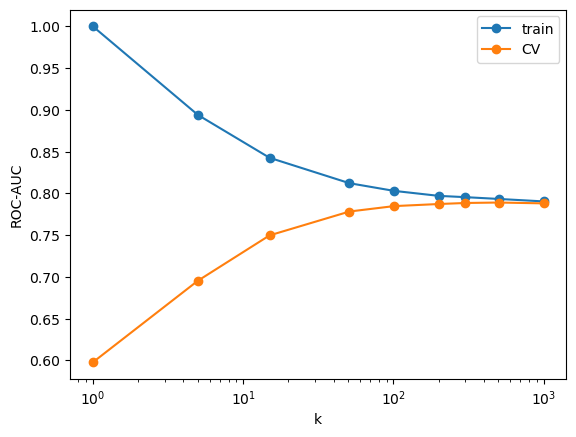

In [41]:
plt.plot(res["param_knn__n_neighbors"], res["mean_train_score"], "o-", label="train")
plt.plot(res["param_knn__n_neighbors"], res["mean_test_score"], "o-", label="CV")
plt.xscale("log"); plt.xlabel("k"); plt.ylabel("ROC-AUC"); plt.legend(); plt.show()

In [42]:
knn.set_params(knn__n_neighbors=best_k).fit(X_train, y_train)
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report
for name, X, y in [("train", X_train, y_train), ("test", X_test, y_test)]:
    p = knn.predict_proba(X)[:, 1]
    print(name, "AUC:", round(roc_auc_score(y, p), 3))
    print(name, "ошибка (1 - accuracy):", round(1 - knn.score(X, y), 3))

train AUC: 0.794
train ошибка (1 - accuracy): 0.194
test AUC: 0.793
test ошибка (1 - accuracy): 0.193


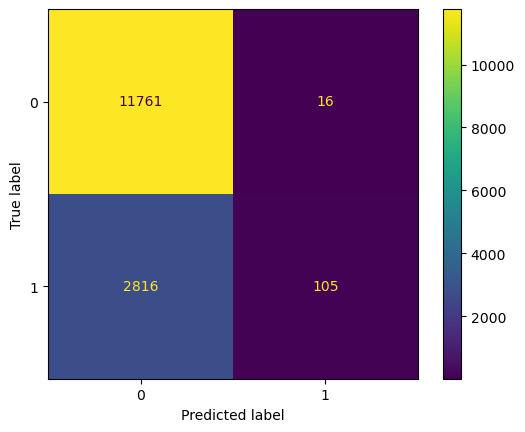

              precision    recall  f1-score   support

           0      0.807     0.999     0.893     11777
           1      0.868     0.036     0.069      2921

    accuracy                          0.807     14698
   macro avg      0.837     0.517     0.481     14698
weighted avg      0.819     0.807     0.729     14698



In [43]:
from sklearn.metrics import ConfusionMatrixDisplay
pred = knn.predict(X_test)
ConfusionMatrixDisplay.from_predictions(y_test, pred); plt.show()
print(classification_report(y_test, pred, digits=3))

In [44]:
from sklearn.dummy import DummyClassifier
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print(classification_report(y_test, dummy.predict(X_test), digits=3, zero_division=0))

              precision    recall  f1-score   support

           0      0.801     1.000     0.890     11777
           1      0.000     0.000     0.000      2921

    accuracy                          0.801     14698
   macro avg      0.401     0.500     0.445     14698
weighted avg      0.642     0.801     0.713     14698



**Выбор k (5-fold CV на train, ROC-AUC):** при k = 1 train AUC = 1.000, CV = 0.598 — модель запоминает обучающие объекты (переобучение). С ростом k AUC на train падает, а на CV растёт; лучший k = 501 (CV = 0.789), при k = 1001 CV уже снижается (0.788).

**Финальная модель (k = 501):** train AUC 0.794 / test AUC 0.793, ошибка 0.194 / 0.193 — переобучения нет.

**Матрица ошибок при пороге 0,5:** recall класса 1 = 0.036 — из 2921 «высоких» модель нашла около 105, то есть 3.6%. Accuracy 0.807 почти как у константной модели (0.801): при дисбалансе 20/80 accuracy не показывает качество (п. 0). Нужен подбор порога (п. 11).

In [45]:
pre_noscale = ColumnTransformer([("num", SimpleImputer(strategy="median"), num + ordc)] + preprocess.transformers[1:])
knn_ns = Pipeline([("prep", pre_noscale), ("knn", KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1))])
knn_ns.fit(X_train, y_train)
print("без нормализации, test AUC:", round(roc_auc_score(y_test, knn_ns.predict_proba(X_test)[:, 1]), 3))

без нормализации, test AUC: 0.609


## 10. Другие классификаторы

In [46]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

def best_threshold(model):
    p = cross_val_predict(model, X_train, y_train, cv=cv5, method="predict_proba", n_jobs=4)[:, 1]
    prec, rec, thr = precision_recall_curve(y_train, p)
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    return thr[f1[:-1].argmax()]

def report(model, thr, name):
    p = model.predict_proba(X_test)[:, 1]
    pred = (p >= thr).astype(int)
    print(f"{name}: test AUC = {roc_auc_score(y_test, p):.3f}, порог = {thr:.3f}")
    ConfusionMatrixDisplay.from_predictions(y_test, pred); plt.title(name); plt.show()
    print(classification_report(y_test, pred, digits=3))

логистическая регрессия: test AUC = 0.794, порог = 0.269


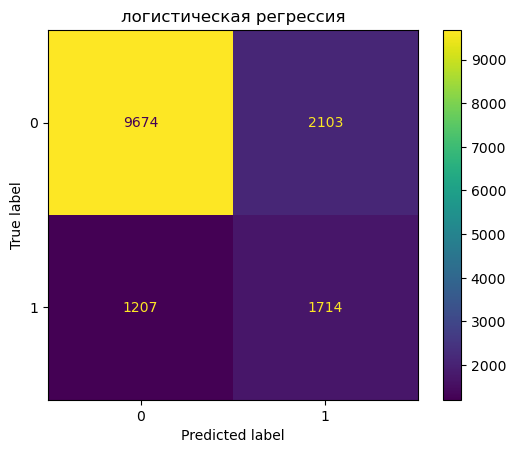

              precision    recall  f1-score   support

           0      0.889     0.821     0.854     11777
           1      0.449     0.587     0.509      2921

    accuracy                          0.775     14698
   macro avg      0.669     0.704     0.681     14698
weighted avg      0.802     0.775     0.785     14698



In [47]:
from sklearn.linear_model import LogisticRegression
logreg = Pipeline([("prep", preprocess), ("lr", LogisticRegression(max_iter=2000))]).fit(X_train, y_train)
thr_lr = best_threshold(logreg)
report(logreg, thr_lr, "логистическая регрессия")

градиентный бустинг: test AUC = 0.807, порог = 0.235


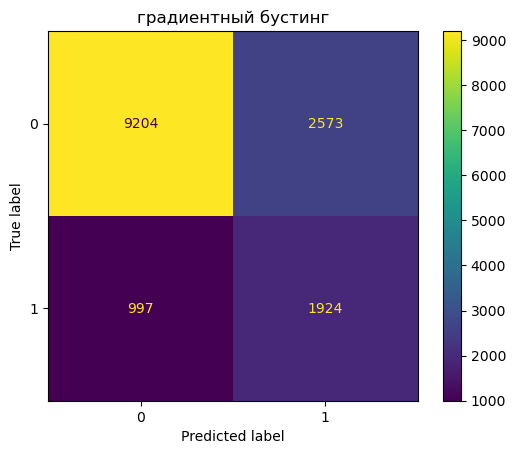

              precision    recall  f1-score   support

           0      0.902     0.782     0.838     11777
           1      0.428     0.659     0.519      2921

    accuracy                          0.757     14698
   macro avg      0.665     0.720     0.678     14698
weighted avg      0.808     0.757     0.774     14698



In [48]:
from sklearn.ensemble import HistGradientBoostingClassifier
hgb = Pipeline([("prep", preprocess), ("hgb", HistGradientBoostingClassifier(random_state=42))]).fit(X_train, y_train)
thr_hgb = best_threshold(hgb)
report(hgb, thr_hgb, "градиентный бустинг")

**Сравнение моделей (test ROC-AUC):** kNN — 0.793, логистическая регрессия — 0.794, градиентный бустинг — 0.807. Три разных по устройству метода дали почти одинаковый результат, значит предел — в информативности признаков, а не в методе. Ориентир из предварительного анализа (бустинг ≈ 0.82) не достигнут: бустинг без настройки гиперпараметров.


## 11. Дисбаланс: подбор порога

kNN, k=501: test AUC = 0.793, порог = 0.194


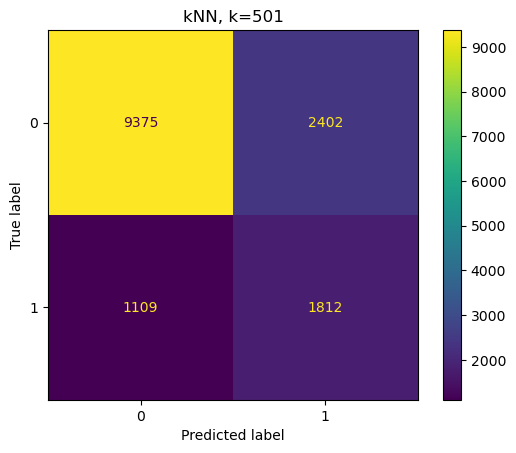

              precision    recall  f1-score   support

           0      0.894     0.796     0.842     11777
           1      0.430     0.620     0.508      2921

    accuracy                          0.761     14698
   macro avg      0.662     0.708     0.675     14698
weighted avg      0.802     0.761     0.776     14698



In [49]:
thr_knn = best_threshold(knn)
report(knn, thr_knn, "kNN, k=501")

**Подбор порога** (по максимуму F1 на предсказаниях кросс-валидации по train, тест не используется): для kNN порог 0.194 вместо 0.5.
- recall класса 1: 0.036 → 0.620; accuracy: 0.807 → 0.761.
- Accuracy упала, но модель стала находить в 17 раз больше «высоких» — ровно пример моделей А и Б из п. 0: жертвуя accuracy увеличиваем recall.
- Точность 0.43 против базовых 0.20: среди названных «высокими» макиавеллистов в 2,2 раза больше, чем при случайном выборе.
- TP можно увеличить, снизив порог, ценой роста ложных срабатываний; порог по F1 — компромисс, а не единственно верный выбор.

## 12. Коррелированные признаки

In [50]:
c = X_train[num + ordc].corr(method="spearman").abs()
pairs = c.where(np.triu(np.ones(c.shape), k=1).astype(bool)).stack().sort_values(ascending=False)
pairs.head(10)

screenw  screenh      0.871422
TIPI1    TIPI6        0.567735
age      education    0.566336
TIPI4    TIPI9        0.551519
TIPI3    TIPI8        0.436575
TIPI2    TIPI7        0.287249
TIPI3    TIPI9        0.283760
TIPI5    TIPI10       0.281668
TIPI1    TIPI5        0.271816
TIPI8    TIPI9        0.233223
dtype: float64

In [51]:
num2 = [c for c in num if c != "screenh"]
pre2 = ColumnTransformer([("num", preprocess.transformers[0][1], num2 + ordc)] + preprocess.transformers[1:])
knn2 = Pipeline([("prep", pre2), ("knn", KNeighborsClassifier(n_neighbors=best_k))]).fit(X_train, y_train)
print("kNN без screenh, test AUC:", round(roc_auc_score(y_test, knn2.predict_proba(X_test)[:, 1]), 3))

kNN без screenh, test AUC: 0.793


**Коррелированные признаки.** Единственная пара с |ρ| > 0.7 — screenw и screenh (0.87). Удаление screenh не изменило test AUC (0.793), поэтому оставляем оба.

Пары TIPI1–TIPI6, TIPI3–TIPI8, TIPI4–TIPI9 коррелируют (|ρ| ≈ 0.44–0.57), и это ожидаемо: каждая пара описывает одну черту «большой пятёрки», один пункт прямой, другой обратный. Исключать их не нужно: корреляция умеренная (~0,5), второй пункт добавляет информацию и снижает шум измерения.

Зачем вообще исключают коррелированные признаки: в kNN одна и та же информация входит в расстояние дважды, получая двойной вес.

## 13. Выводы

1. **Ответ на вопрос.** Высокий макиавеллизм (верхние 20% балла) по личности (TIPI), демографии и словарному тесту предсказывается относительно точно (умеренная корреляция): лучший test AUC 0.807. Три разных метода сошлись на AUC ≈ 0.79–0.81 — это предел информативности признаков, а не слабость метода.
2. **Модели.** Градиентный бустинг — AUC 0.807, recall класса 1 = 0.659 при подобранном пороге; kNN (k = 501) — 0.793 / 0.620; логистическая регрессия — 0.794 / 0.587. Худшая — константная модель: recall 0.
3. **Что связано с баллом.** Сильнее всего — отрицательно коррелирует признак типа личности «сочувствующий, тёплый» (TIPI7, ρ = −0.44) и положительно коррелирует «критичный, склонный спорить» (TIPI2, +0.32), из демографии — возраст (ρ = −0.23) и пол (медианный балл у мужчин ≈ 73 против ≈ 63 у женщин); эффект образования объясняется возрастом; выдуманные слова: доля класса 1 растёт с 17,7% до 42,8%.
4. **Что было критично:** нормализация для kNN (AUC 0.609 → 0.793); подбор порога при дисбалансе 20/80 (recall 0.036 → 0.620); исключение признаков, которые существуют только при прохождении теста (утечка).
5. **Ограничения:** выборка — добровольцы из интернета, не представительная; связи корреляционные, не причинные; выводы не стоит экстраполировать результаты на большие группы людей, нужно учитывать специфику выборки.